In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("customers_dirty.csv")

print("Данные успешно загружены")
df.head()

Данные успешно загружены


,customer_id,age,monthly_income,city,visits_per_month,satisfaction_score
0,1,19.0,18000.0,Бишкек,5,8.0
1,2,22.0,25000.0,Ош,8,9.0
2,3,25.0,32000.0,Бишкек,12,7.0
3,4,31.0,45000.0,Каракол,6,8.0
4,5,28.0,38000.0,Ош,10,9.0


In [2]:
print("Размер таблицы:", df.shape)

print("\nИнформация о столбцах:")
df.info()

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nОсновная статистика:")
df.describe()

Размер таблицы: (30, 6)

Информация о столбцах:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         30 non-null     int64  
 1   age                 29 non-null     float64
 2   monthly_income      29 non-null     float64
 3   city                30 non-null     str    
 4   visits_per_month    30 non-null     int64  
 5   satisfaction_score  29 non-null     float64
dtypes: float64(3), int64(2), str(1)
memory usage: 1.5 KB

Количество пропусков:
customer_id           0
age                   1
monthly_income        1
city                  0
visits_per_month      0
satisfaction_score    1
dtype: int64

Основная статистика:


,customer_id,age,monthly_income,visits_per_month,satisfaction_score
count,30.000000,29.000000,29.000000,30.000000,29.000000
mean,15.500000,35.448276,68344.827586,10.700000,7.931034
std,8.803408,40.806675,170085.540635,14.932376,0.923156
min,1.000000,18.000000,15000.000000,3.000000,6.000000
25%,8.250000,23.000000,27000.000000,6.000000,7.000000
50%,15.500000,28.000000,38000.000000,8.000000,8.000000
75%,22.750000,33.000000,47000.000000,10.000000,9.000000
max,30.000000,245.000000,950000.000000,88.000000,9.000000


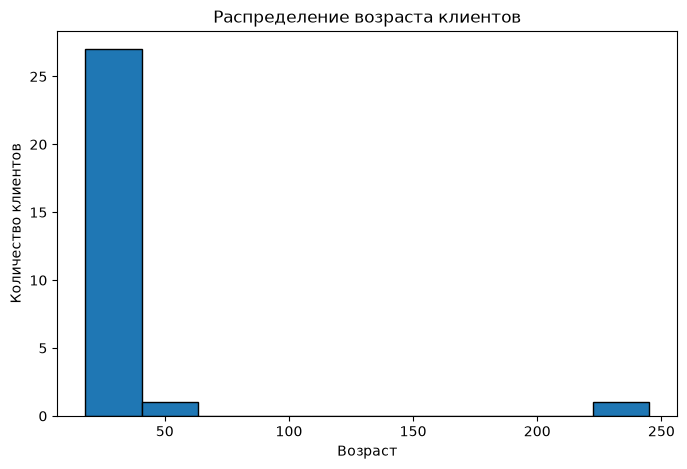

In [3]:
plt.figure(figsize=(8, 5))
plt.hist(df["age"].dropna(), bins=10, edgecolor="black")
plt.title("Распределение возраста клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество клиентов")
plt.show()

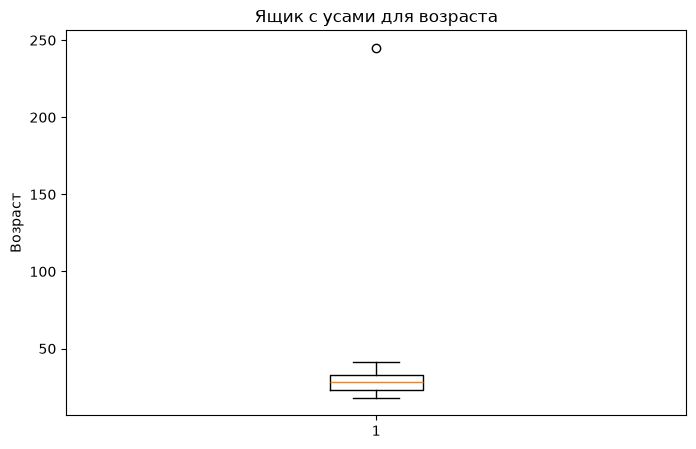

Возраст больше 100 лет:
   customer_id    age
5            6  245.0


In [4]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["age"].dropna())
plt.title("Ящик с усами для возраста")
plt.ylabel("Возраст")
plt.show()

print("Возраст больше 100 лет:")
print(df[df["age"] > 100][["customer_id", "age"]])

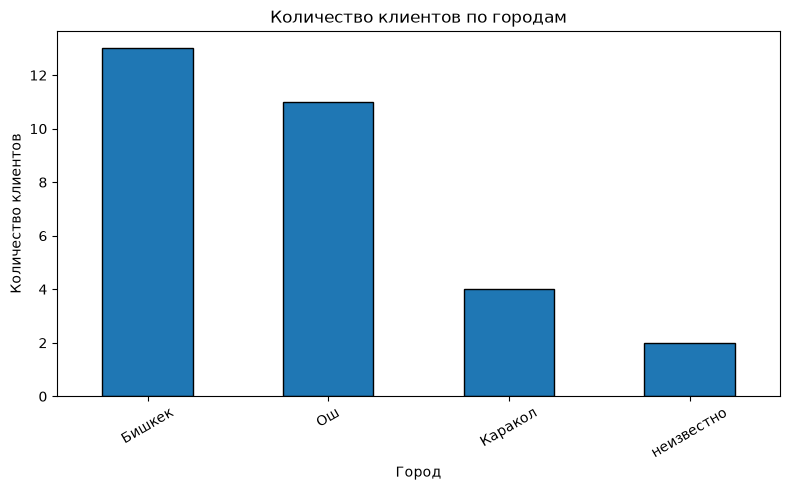

In [5]:
city_counts = df["city"].fillna("Пропуск").value_counts()

plt.figure(figsize=(8, 5))
city_counts.plot(kind="bar", edgecolor="black")
plt.title("Количество клиентов по городам")
plt.xlabel("Город")
plt.ylabel("Количество клиентов")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [6]:
print("Подозрительный возраст:")
print(df[df["age"] > 100])

print("\nПодозрительный доход:")
print(df[df["monthly_income"] > 150000])

print("\nПодозрительное количество посещений:")
print(df[df["visits_per_month"] > 30])

Подозрительный возраст:
   customer_id    age  monthly_income    city  visits_per_month  \
5            6  245.0         40000.0  Бишкек                 7   

   satisfaction_score  
5                 6.0  

Подозрительный доход:
    customer_id   age  monthly_income    city  visits_per_month  \
13           14  41.0        950000.0  Бишкек                 8   

    satisfaction_score  
13                 7.0  

Подозрительное количество посещений:
    customer_id   age  monthly_income    city  visits_per_month  \
11           12  33.0         48000.0  Бишкек                88   

    satisfaction_score  
11                 9.0  


In [7]:
issues = pd.DataFrame({
    "Проблема данных": [
        "Пропущенные значения",
        "Выбросы возраста",
        "Выбросы дохода",
        "Выбросы посещений",
        "Несогласованные категории"
    ],
    "Где обнаружена": [
        "age, monthly_income, satisfaction_score",
        "age = 245",
        "monthly_income = 950000",
        "visits_per_month = 88",
        "city: неизвестно"
    ]
})

issues

,Проблема данных,Где обнаружена
0,Пропущенные значения,"age, monthly_income, satisfaction_score"
1,Выбросы возраста,age = 245
2,Выбросы дохода,monthly_income = 950000
3,Выбросы посещений,visits_per_month = 88
4,Несогласованные категории,city: неизвестно


In [8]:
print("""
В ходе разведочного анализа данных были выполнены:
1. Загрузка и просмотр данных.
2. Проверка пропущенных значений.
3. Построение гистограммы возраста.
4. Построение boxplot для поиска выбросов.
5. Построение столбчатой диаграммы городов.
6. Поиск подозрительных значений.
7. Составление таблицы проблем данных.

Для дальнейшей обработки необходимо проверить выбросы,
обработать пропуски и привести категории к единому формату.
""")


В ходе разведочного анализа данных были выполнены:
1. Загрузка и просмотр данных.
2. Проверка пропущенных значений.
3. Построение гистограммы возраста.
4. Построение boxplot для поиска выбросов.
5. Построение столбчатой диаграммы городов.
6. Поиск подозрительных значений.
7. Составление таблицы проблем данных.

Для дальнейшей обработки необходимо проверить выбросы,
обработать пропуски и привести категории к единому формату.

